In [1]:
#1. 导入必要的库
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

In [2]:
#2. 加载数据
# 加载鸢尾花数据集
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
class_names = iris.target_names

# 创建数据框以便更好地查看数据
df = pd.DataFrame(X, columns=feature_names)
df['species'] = y
df['species'] = df['species'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})

print("数据集前5行:")
print(df.head())
print("\n数据集信息:")
print(df.info())
print("\n各类别样本数量:")
print(df['species'].value_counts())

数据集前5行:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

数据集信息:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    objec

C:\Users\kim\AppData\Local\Temp\ipykernel_24644\2784091036.py:12: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kim\AppData\Local\Temp\ipykernel_24644\2784091036.py:12: UserWarning: Glyph 24067 (\N{CJK UNIFIED IDEOGRAPH-5E03}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 24067 (\N{CJK UNIFIED IDEOGRAPH-5E03}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


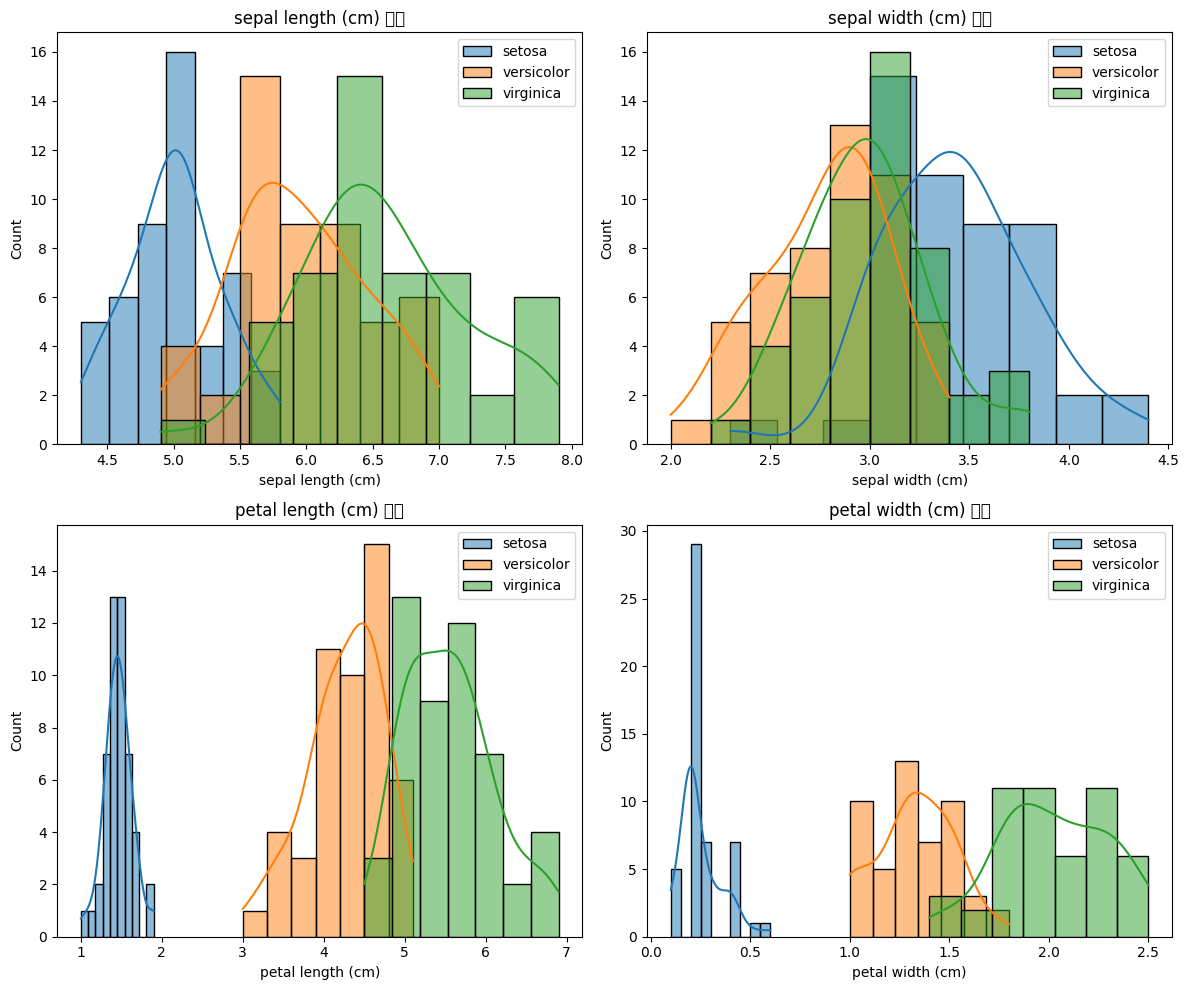

C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 40482 (\N{CJK UNIFIED IDEOGRAPH-9E22}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 23614 (\N{CJK UNIFIED IDEOGRAPH-5C3E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 33457 (\N{CJK UNIFIED IDEOGRAPH-82B1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 

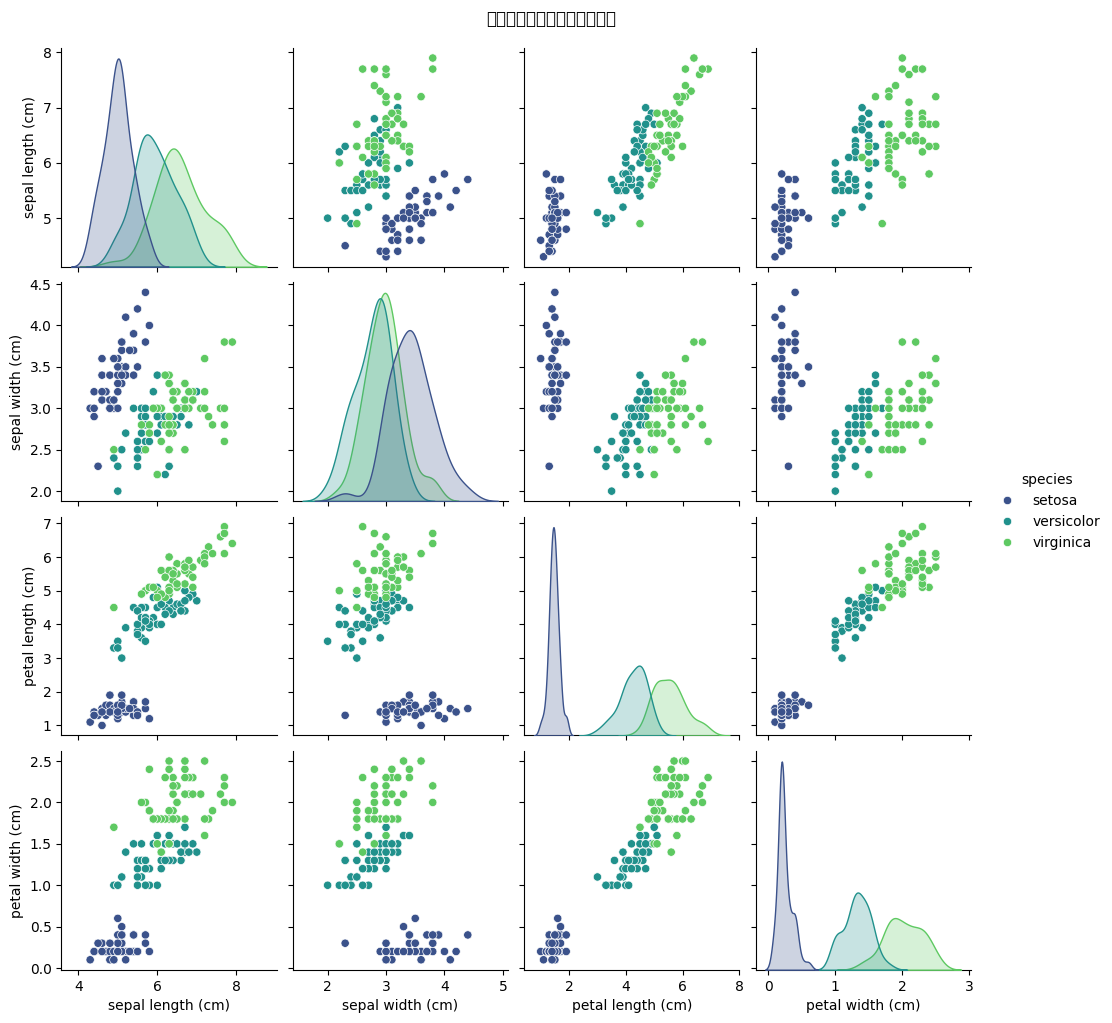

In [3]:
#3. 数据探索和可视化
# 绘制特征分布图
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, feature in enumerate(feature_names):
    row, col = i // 2, i % 2
    for species in class_names:
        sns.histplot(df[df['species'] == species][feature], 
                     kde=True, label=species, ax=axes[row, col])
    axes[row, col].set_title(f'{feature} 分布')
    axes[row, col].legend()

plt.tight_layout()
plt.show()

# 绘制特征之间的散点图矩阵
sns.pairplot(df, hue='species', palette='viridis')
plt.suptitle('鸢尾花数据集特征散点图矩阵', y=1.02)
plt.show()

In [4]:
#4. 划分训练集和测试集
# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"训练集大小: {X_train.shape[0]}")
print(f"测试集大小: {X_test.shape[0]}")

训练集大小: 105
测试集大小: 45


In [5]:
#5. 创建和训练决策树模型
# 创建决策树分类器
dt_classifier = DecisionTreeClassifier(
    criterion='gini',  # 使用基尼系数作为分裂标准
    max_depth=3,       # 限制树的最大深度，防止过拟合
    random_state=42
)

# 训练模型
dt_classifier.fit(X_train, y_train)

# 在训练集和测试集上进行预测
y_train_pred = dt_classifier.predict(X_train)
y_test_pred = dt_classifier.predict(X_test)

训练集准确率: 0.9810
测试集准确率: 0.9778

分类报告:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 31614 (\N{CJK UNIFIED IDEOGRAPH-7B7E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 

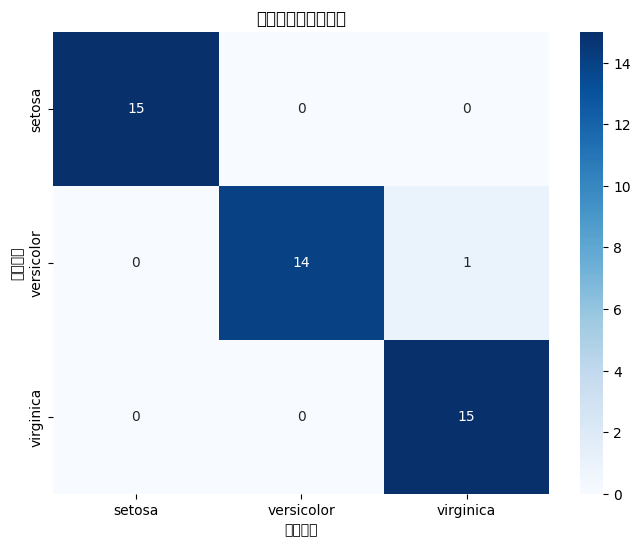

In [6]:
#6. 模型评估
# 计算准确率
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"训练集准确率: {train_accuracy:.4f}")
print(f"测试集准确率: {test_accuracy:.4f}")

# 显示分类报告
print("\n分类报告:")
print(classification_report(y_test, y_test_pred, target_names=class_names))

# 绘制混淆矩阵
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('决策树分类混淆矩阵')
plt.ylabel('真实标签')
plt.xlabel('预测标签')
plt.show()

C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 40482 (\N{CJK UNIFIED IDEOGRAPH-9E22}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 23614 (\N{CJK UNIFIED IDEOGRAPH-5C3E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 33457 (\N{CJK UNIFIED IDEOGRAPH-82B1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 

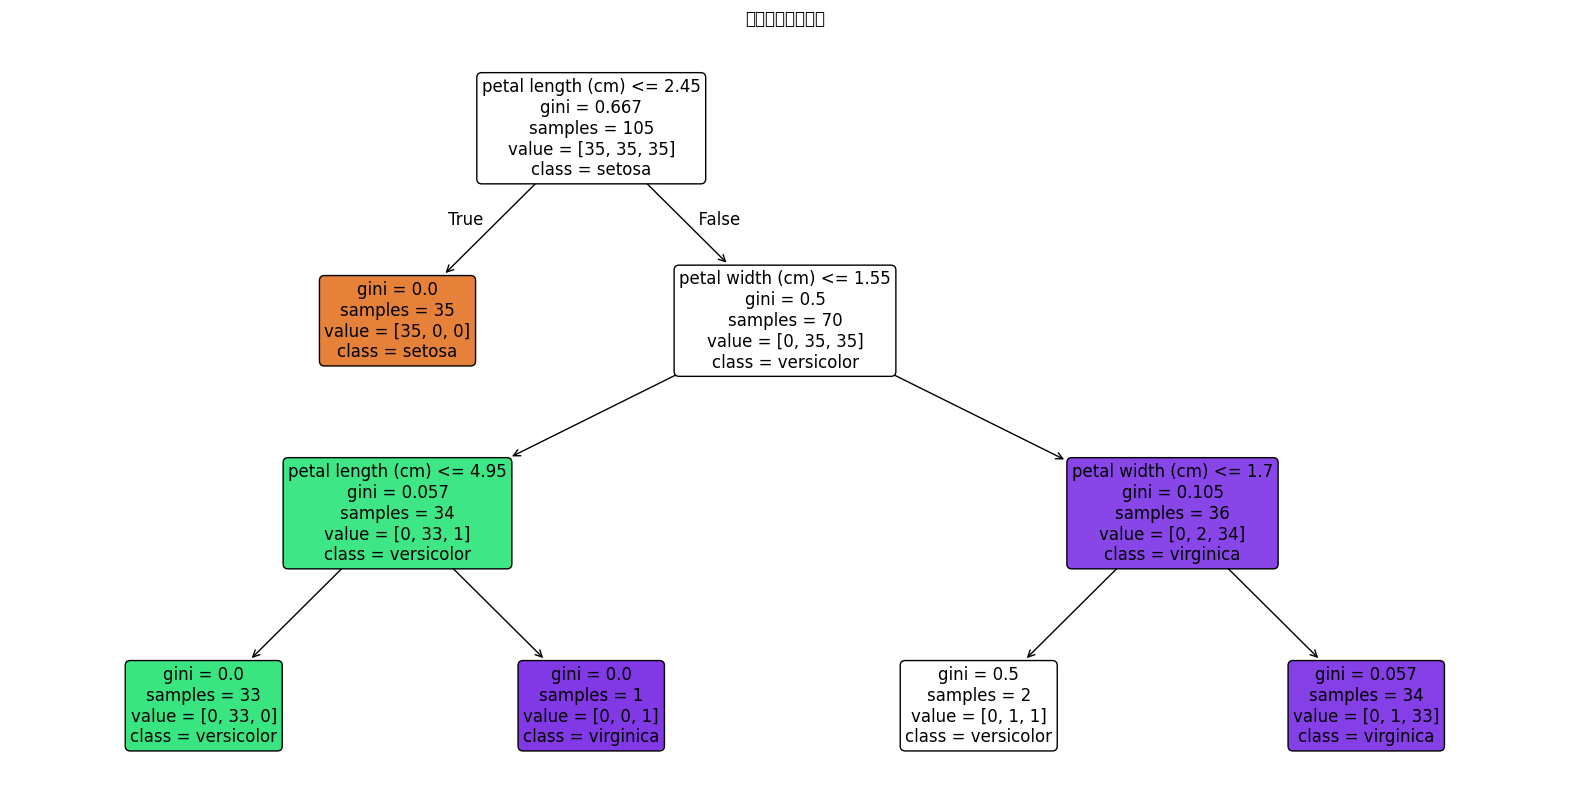

C:\Users\kim\AppData\Local\Temp\ipykernel_24644\1691578181.py:21: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kim\AppData\Local\Temp\ipykernel_24644\1691578181.py:21: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kim\AppData\Local\Temp\ipykernel_24644\1691578181.py:21: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kim\AppData\Local\Temp\ipykernel_24644\1691578181.py:21: UserWarning: Glyph 35201 (\N{CJK UNIFIED IDEOGRAPH-8981}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kim\AppData\Local\Temp\ipykernel_24644\1691578181.py:21: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Gly

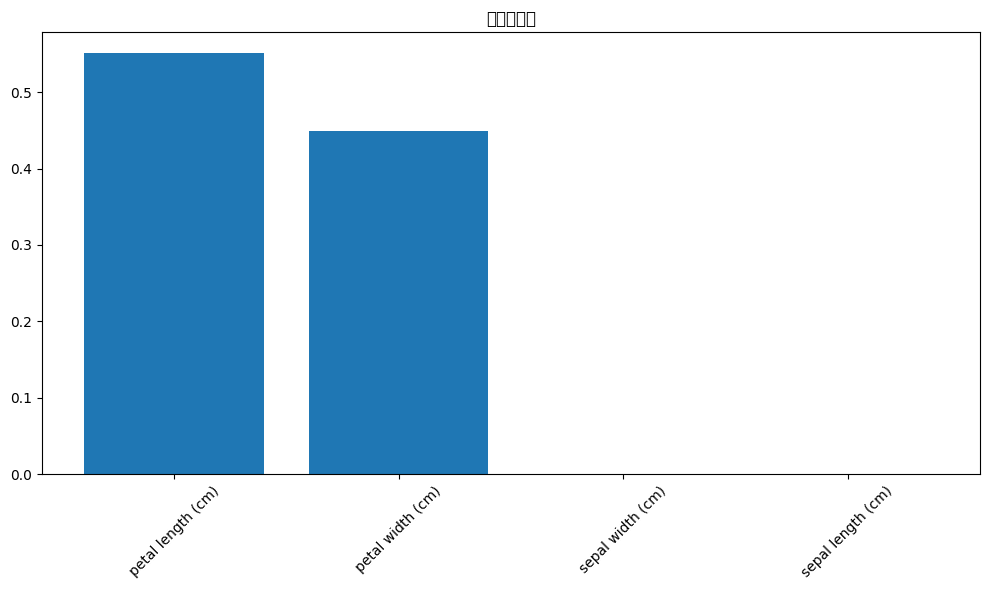

特征重要性排序:
1. petal length (cm): 0.5509
2. petal width (cm): 0.4491
3. sepal width (cm): 0.0000
4. sepal length (cm): 0.0000


In [7]:
#7. 可视化决策树
# 绘制决策树
plt.figure(figsize=(20, 10))
plot_tree(dt_classifier, 
          feature_names=feature_names, 
          class_names=class_names, 
          filled=True, 
          rounded=True, 
          fontsize=12)
plt.title('鸢尾花分类决策树')
plt.show()

# 特征重要性分析
feature_importance = dt_classifier.feature_importances_
indices = np.argsort(feature_importance)[::-1]

plt.figure(figsize=(10, 6))
plt.title("特征重要性")
plt.bar(range(X.shape[1]), feature_importance[indices])
plt.xticks(range(X.shape[1]), [feature_names[i] for i in indices], rotation=45)
plt.tight_layout()
plt.show()

print("特征重要性排序:")
for i, idx in enumerate(indices):
    print(f"{i+1}. {feature_names[idx]}: {feature_importance[idx]:.4f}")

C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 20915 (\N{CJK UNIFIED IDEOGRAPH-51B3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 31574 (\N{CJK UNIFIED IDEOGRAPH-7B56}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 26641 (\N{CJK UNIFIED IDEOGRAPH-6811}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 36793 (\N{CJK UNIFIED IDEOGRAPH-8FB9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\kim\.virtualenvs\cv2-AFZlAyVW\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 

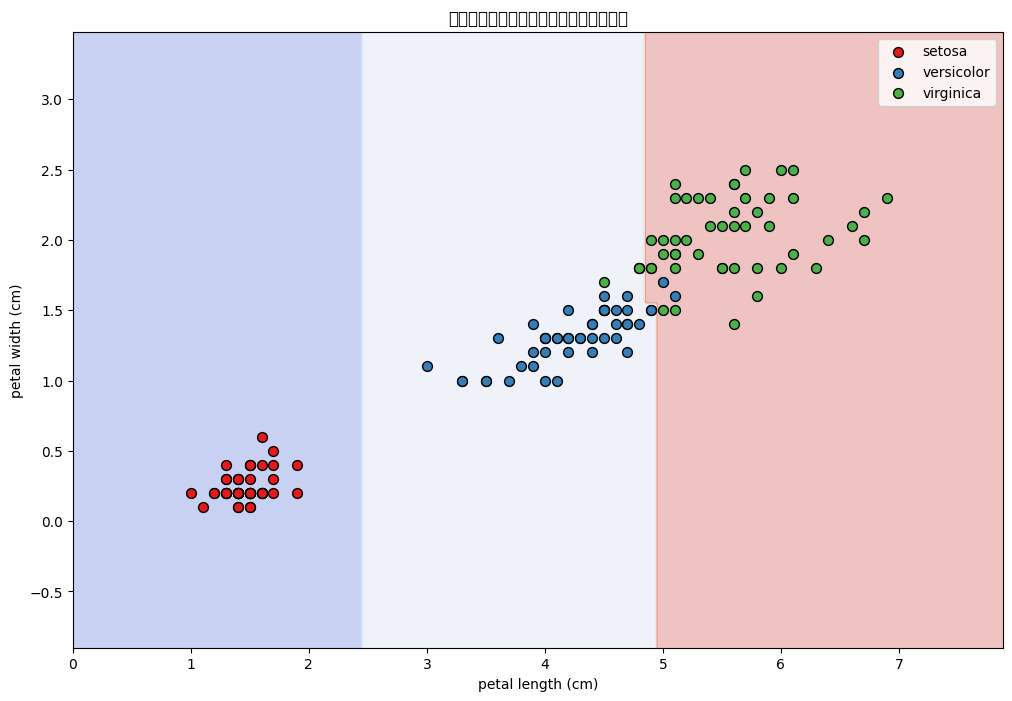

In [8]:
#8. 决策边界可视化
# 由于有4个特征，我们选择两个最重要的特征进行可视化
# 选择最重要的两个特征
top_features = indices[:2]

# 只用这两个特征重新训练一个决策树
X_reduced = X[:, top_features]
X_train_red, X_test_red, y_train, y_test = train_test_split(
    X_reduced, y, test_size=0.3, random_state=42, stratify=y
)

dt_classifier_red = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_classifier_red.fit(X_train_red, y_train)

# 创建网格以便绘制决策边界
x_min, x_max = X_reduced[:, 0].min() - 1, X_reduced[:, 0].max() + 1
y_min, y_max = X_reduced[:, 1].min() - 1, X_reduced[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# 预测网格点的类别
Z = dt_classifier_red.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 绘制决策边界
plt.figure(figsize=(12, 8))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)

# 绘制训练点
for i, class_name in enumerate(class_names):
    plt.scatter(X_reduced[y == i, 0], 
                X_reduced[y == i, 1], 
                c=[plt.cm.Set1(i)], 
                label=class_name, 
                edgecolor='black', s=50)

plt.xlabel(feature_names[top_features[0]])
plt.ylabel(feature_names[top_features[1]])
plt.title("决策树决策边界（基于两个最重要特征）")
plt.legend()
plt.show()